# Análisis exploratorio del dataset

Caltech Camera Traps (CCT) completo: 243,100 imágenes de 140 cámaras. Este notebook describe el dataset tal como se usa en el proyecto (16 clases, vacías como fondo), muestra ejemplos de las imágenes y genera las figuras del informe en `reports/figures/`.

Solo necesita las anotaciones (`data/raw/annotations/`). Para los ejemplos usa las imágenes de `data/raw/cct_images/` si ya están extraídas; si no, descarga solo esas fotos desde el bucket público de LILA a `data/cache/eda/`.

In [1]:
import json
import random
import sys
import urllib.request
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data.coco_to_yolo import EXCLUDED, FULL_FRAME  # mismas reglas que el conversor

ANN = ROOT / 'data' / 'raw' / 'annotations'
IMG_DIR = ROOT / 'data' / 'raw' / 'cct_images'
CACHE = ROOT / 'data' / 'cache' / 'eda'
FIG = ROOT / 'reports' / 'figures'
LILA = 'https://storage.googleapis.com/public-datasets-lila/caltech-unzipped/cct_images/'
FIG.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e5e4e0'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
})
rng = random.Random(0)


def load(name):
    with open(ANN / name, encoding='utf-8') as f:
        return json.load(f)


def image_path(file_name):
    local = IMG_DIR / file_name
    if local.exists():
        return local
    cached = CACHE / file_name
    if not cached.exists():
        urllib.request.urlretrieve(LILA + file_name, cached)
    return cached


def show_examples(examples, ncols, title, fname, width=3.2):
    # examples: lista de dicts con file_name, caption y opcionalmente boxes [(x, y, w, h, etiqueta)]
    nrows = -(-len(examples) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, width * 0.78 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, ex in zip(axes.flat, examples):
        img = Image.open(image_path(ex['file_name']))
        scale = 800 / max(img.size)
        img = img.resize((round(img.width * scale), round(img.height * scale)))
        ax.imshow(img)
        for x, y, w, h, label in ex.get('boxes', []):
            ax.add_patch(Rectangle((x * scale, y * scale), w * scale, h * scale,
                                   fill=False, edgecolor=ORANGE, linewidth=2))
            if label:
                # Si la caja toca el borde superior, la etiqueta va por dentro
                ty = y * scale - 6 if y * scale > 20 else y * scale + 16
                ax.text(x * scale + 2, ty, label, color='white', fontsize=7,
                        bbox=dict(facecolor=ORANGE, edgecolor='none', pad=1.5))
        ax.set_title(ex['caption'], fontsize=8, fontweight='normal', color=INK_2)
    fig.suptitle(title, fontsize=11, fontweight='bold')
    fig.tight_layout()
    fig.savefig(FIG / fname)
    plt.show()


def boxes_of(image_id, frame=None):
    df = boxes_all if frame is None else frame
    return [(*b, s) for b, s in df.loc[df['image_id'] == image_id, ['bbox', 'species']].values]


def caption(row, extra=''):
    hour = row['datetime'].strftime('%H:%M') if pd.notna(row['datetime']) else '—'
    return f"{extra}cámara {row['location']} · {hour}"

## Carga de anotaciones

In [2]:
meta = load('caltech_images_20210113.json')
bboxes = load('caltech_bboxes_20200316.json')

cat_name = {c['id']: c['name'] for c in meta['categories']}
labels = defaultdict(set)
for a in meta['annotations']:
    labels[a['image_id']].add(cat_name[a['category_id']])

images = pd.DataFrame(meta['images'])
images['location'] = images['location'].astype(str)
images['species'] = images['id'].map(lambda i: labels[i] - {'empty'})
images['empty'] = images['species'].map(len) == 0
images['datetime'] = pd.to_datetime(images['date_captured'], errors='coerce')
images['night'] = images['datetime'].dt.hour.isin(list(range(0, 6)) + list(range(19, 24)))
by_id = images.set_index('id')

boxes_all = pd.DataFrame(bboxes['annotations'])
boxes_all['species'] = boxes_all['category_id'].map(cat_name)
boxes_all = boxes_all.join(by_id[['width', 'height']], on='image_id')
boxes_all['rel_area'] = boxes_all['bbox'].map(lambda b: b[2] * b[3]) / (boxes_all['width'] * boxes_all['height'])
# Cajas usadas en el proyecto: sin clases excluidas, sin "car" ni la categoría "empty"
boxes = boxes_all[~boxes_all['species'].isin(EXCLUDED | FULL_FRAME | {'empty'})]

print(f"Imágenes: {len(images):,} | cámaras: {images['location'].nunique()} | "
      f"vacías: {images['empty'].sum():,} ({images['empty'].mean():.1%})")
print(f"Cajas (16 clases): {len(boxes):,} en {boxes['image_id'].nunique():,} imágenes")

Imágenes: 243,100 | cámaras: 140 | vacías: 125,745 (51.7%)
Cajas (16 clases): 62,361 en 59,200 imágenes


## Prevalencia por especie

Número de cajas por especie en las imágenes utilizables. El desbalance es extremo: la especie más común (opossum) tiene cientos de veces más ejemplos que las más raras (badger, mountain_lion).

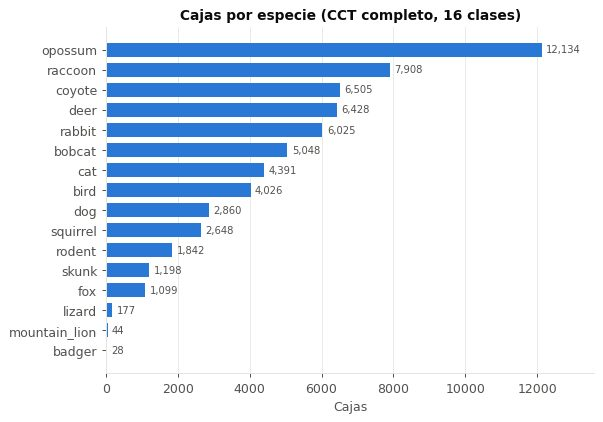

Razón más común / más rara: 433x


In [3]:
counts = boxes['species'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(counts.index, counts.values, color=BLUE, height=0.7)
for y, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, y, f'{v:,}', va='center', fontsize=8, color=INK_2)
ax.set_xlabel('Cajas')
ax.set_title('Cajas por especie (CCT completo, 16 clases)')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, counts.max() * 1.12)
fig.savefig(FIG / 'eda_cajas_por_especie.png')
plt.show()

print(f'Razón más común / más rara: {counts.max() / counts.min():.0f}x')

### Ejemplos: una foto por especie

Para cada especie se elige al azar una foto con una sola caja de tamaño típico para esa especie (entre los percentiles 25 y 75 de su área relativa).

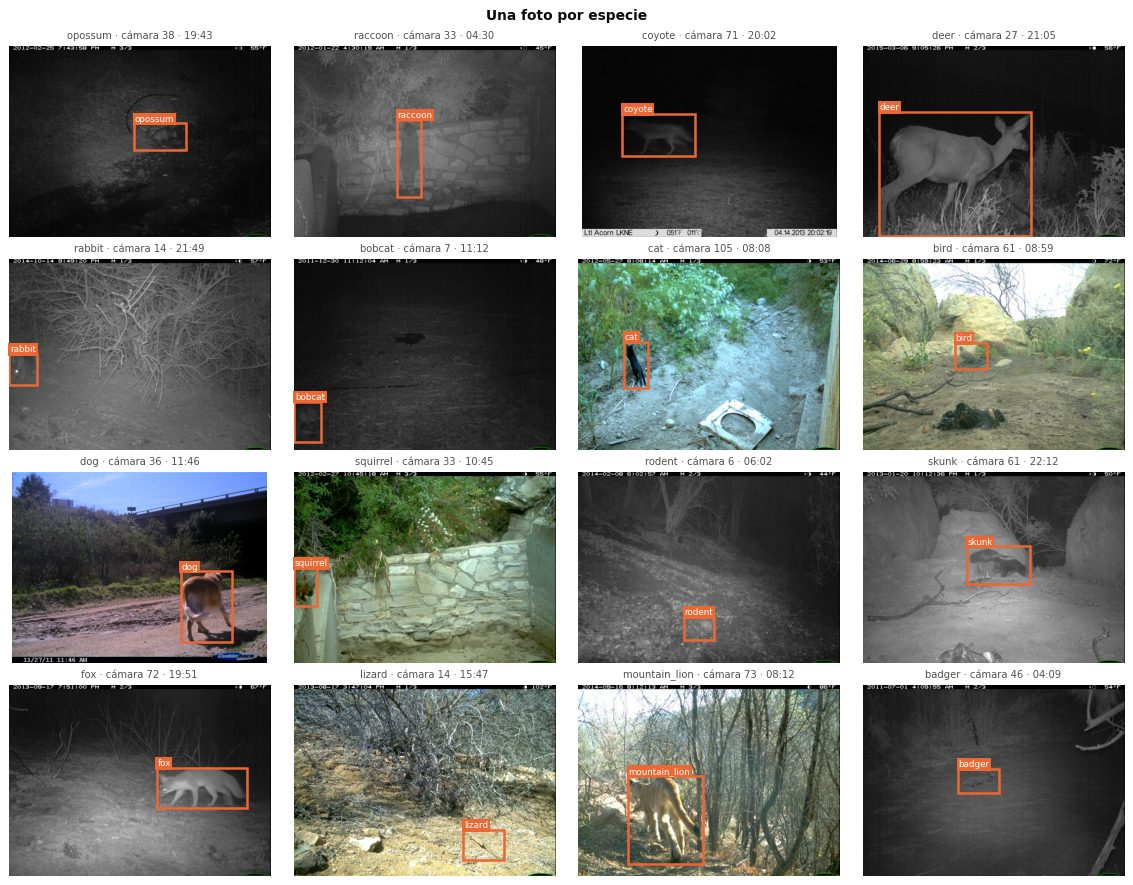

In [4]:
single = boxes[boxes['image_id'].map(boxes['image_id'].value_counts()) == 1]
examples = []
for sp in counts.index[::-1]:
    df = single[single['species'] == sp]
    lo, hi = df['rel_area'].quantile([0.25, 0.75])
    pool = df[df['rel_area'].between(lo, hi)]
    row = pool.iloc[rng.randrange(len(pool))]
    examples.append({'file_name': by_id.loc[row['image_id'], 'file_name'],
                     'boxes': boxes_of(row['image_id'], boxes),
                     'caption': caption(by_id.loc[row['image_id']], f'{sp} · ')})
show_examples(examples, 4, 'Una foto por especie', 'eda_ejemplos_especies.png')

## Composición de las particiones

Imágenes vacías (fondo) frente a imágenes con al menos una caja, por partición. Las cifras vienen de `results/dataset_summary.csv`, generado por el conversor.

,camaras,imagenes,vacias,con_caja,cajas
particion,,,,,
full_train,76,113642,94856,18786,19861
full_val,19,12580,8867,3713,3884
full_test,39,43292,19892,23400,24662
eccv_train,10,11201,0,11201,11693
eccv_cis_val,10,2573,979,1594,1691
eccv_cis_test,10,12858,1151,11707,12263
eccv_trans_test,9,18140,1732,16408,17125


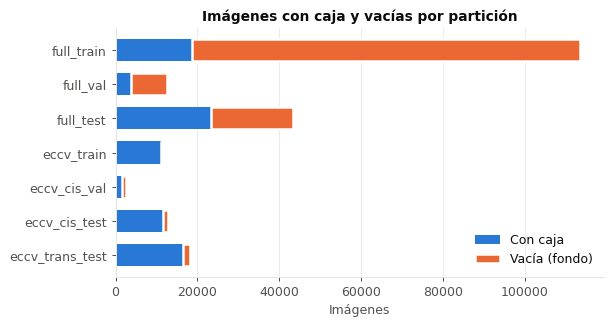

In [5]:
summary = pd.read_csv(ROOT / 'results' / 'dataset_summary.csv').set_index('particion')
display(summary[['camaras', 'imagenes', 'vacias', 'con_caja', 'cajas']])

order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(order, summary.loc[order, 'con_caja'], color=BLUE, height=0.65, label='Con caja')
ax.barh(order, summary.loc[order, 'vacias'], left=summary.loc[order, 'con_caja'], color=ORANGE,
        height=0.65, label='Vacía (fondo)', edgecolor='white', linewidth=2)
ax.set_xlabel('Imágenes')
ax.set_title('Imágenes con caja y vacías por partición')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower right')
fig.savefig(FIG / 'eda_particiones.png')
plt.show()

## Imágenes vacías por cámara

Proporción de imágenes vacías en cada una de las 140 cámaras. La tasa varía mucho entre cámaras (viento, vegetación, iluminación), lo que muestra que el fondo de cada cámara condiciona lo que el modelo ve.

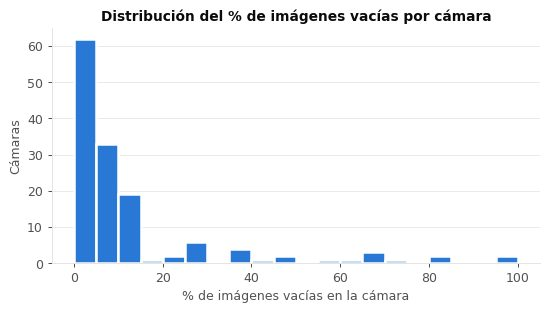

count    140.000
mean       0.134
std        0.202
min        0.000
10%        0.001
50%        0.059
90%        0.382
max        0.976
Name: vacias, dtype: float64


In [6]:
by_cam = images.groupby('location').agg(imagenes=('id', 'size'), vacias=('empty', 'mean'))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(by_cam['vacias'] * 100, bins=20, range=(0, 100), color=BLUE, edgecolor='white', linewidth=2)
ax.set_xlabel('% de imágenes vacías en la cámara')
ax.set_ylabel('Cámaras')
ax.set_title('Distribución del % de imágenes vacías por cámara')
ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'eda_vacias_por_camara.png')
plt.show()

print(by_cam['vacias'].describe(percentiles=[.1, .5, .9]).round(3))

### Ejemplos: imágenes vacías

Activaciones del sensor sin ningún animal (viento, vegetación, cambios de luz). Son el 51.7 % del dataset y el modelo debe aprender a no detectar nada en ellas.

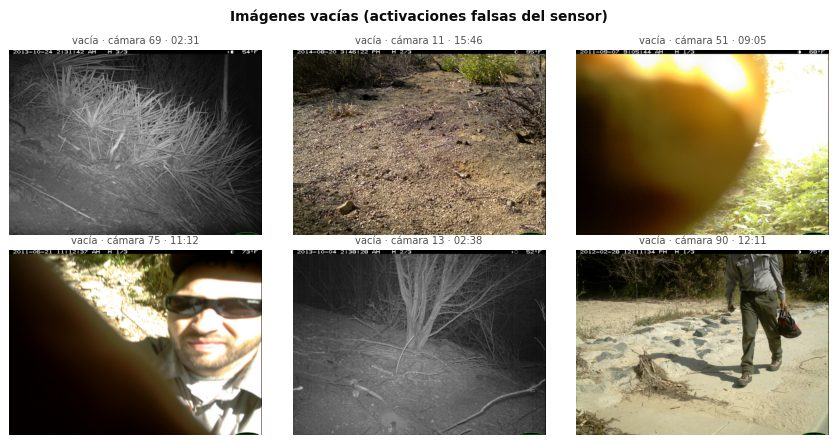

In [7]:
empties = images[images['empty']]
cams = rng.sample(sorted(empties['location'].unique()), 6)
examples = []
for cam in cams:
    pool = empties[empties['location'] == cam]
    row = pool.iloc[rng.randrange(len(pool))]
    examples.append({'file_name': row['file_name'], 'caption': caption(row, 'vacía · ')})
show_examples(examples, 3, 'Imágenes vacías (activaciones falsas del sensor)', 'eda_ejemplos_vacias.png')

### Ejemplos: el fondo fijo de una cámara

Seis fotos de una misma cámara. El fondo (rocas, troncos, encuadre) se repite en todas: un modelo puede asociar ese fondo con las especies que suelen aparecer ahí en lugar de aprender los rasgos del animal. Por eso las particiones se separan por cámara y se evalúa en cámaras nunca vistas (E3).

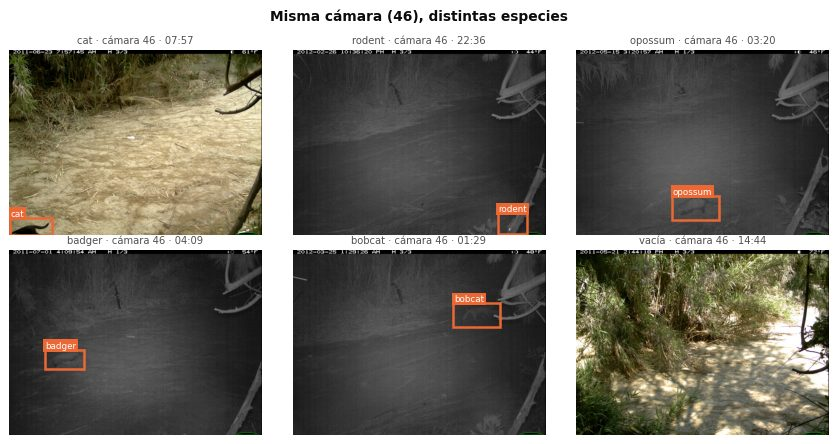

In [8]:
cam_counts = boxes.join(by_id['location'], on='image_id').groupby('location')['species'].nunique()
cam = cam_counts.idxmax()
pool_animal = boxes[boxes['image_id'].map(by_id['location']) == cam].drop_duplicates('image_id')
picked = pool_animal.groupby('species').head(1).sample(5, random_state=0)
examples = [{'file_name': by_id.loc[r['image_id'], 'file_name'], 'boxes': boxes_of(r['image_id'], boxes),
             'caption': caption(by_id.loc[r['image_id']], f"{r['species']} · ")} for _, r in picked.iterrows()]
pool_empty = empties[empties['location'] == cam]
if len(pool_empty):
    row = pool_empty.iloc[rng.randrange(len(pool_empty))]
    examples.append({'file_name': row['file_name'], 'caption': caption(row, 'vacía · ')})
show_examples(examples, 3, f'Misma cámara ({cam}), distintas especies', 'eda_ejemplos_misma_camara.png')

## Tamaño relativo de las cajas

Área de cada caja como fracción del área de la imagen (escala logarítmica). Se usa para definir los grupos de tamaño del análisis de robustez (E4).

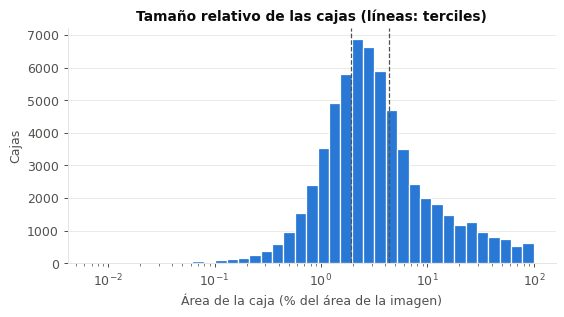

Terciles (% del área): [np.float64(1.93), np.float64(4.31)]
species
rodent            1.16
squirrel          1.39
badger            1.51
rabbit            1.59
lizard            1.64
bird              1.72
opossum           2.16
bobcat            2.70
cat               2.92
raccoon           3.33
skunk             3.46
coyote            5.15
dog               5.23
fox               8.02
mountain_lion     8.29
deer             19.93


In [9]:
pct = boxes['rel_area'] * 100

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(pct, bins=np.logspace(np.log10(pct.min()), np.log10(pct.max()), 40),
        color=BLUE, edgecolor='white', linewidth=1)
ax.set_xscale('log')
terciles = [pct.quantile(q) for q in (1 / 3, 2 / 3)]
for t in terciles:
    ax.axvline(t, color=INK_2, linewidth=1, linestyle='--')
ax.set_xlabel('Área de la caja (% del área de la imagen)')
ax.set_ylabel('Cajas')
ax.set_title('Tamaño relativo de las cajas (líneas: terciles)')
ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'eda_tamano_cajas.png')
plt.show()

print('Terciles (% del área):', [round(t, 2) for t in terciles])
print(pct.groupby(boxes['species']).median().sort_values().round(2).to_string())

### Ejemplos: cajas pequeñas, medianas y grandes

Dos ejemplos de cada tercil de tamaño. Los animales pequeños o lejanos ocupan una fracción mínima de la imagen y son los más difíciles de detectar.

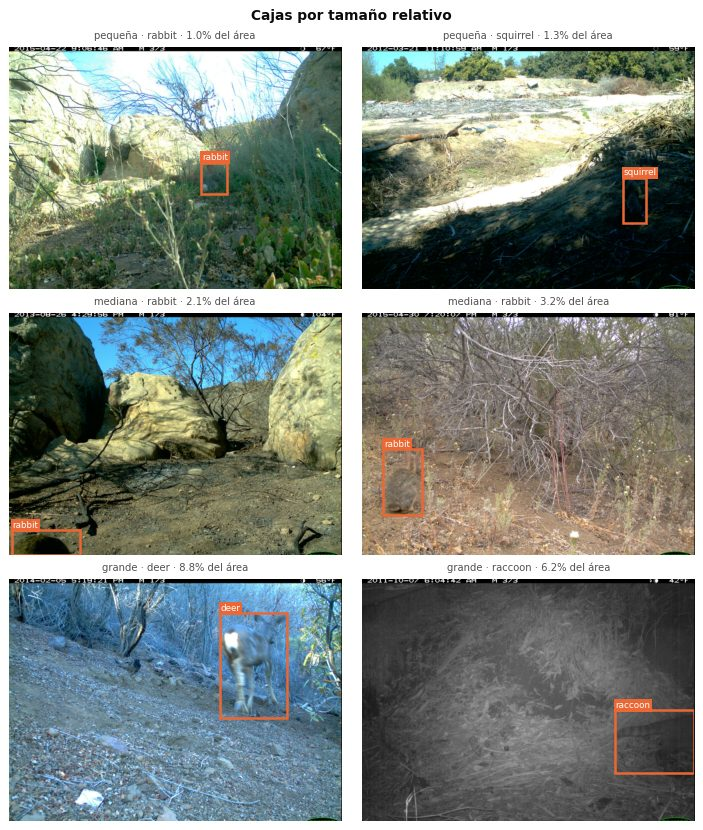

In [10]:
lo, hi = [t / 100 for t in terciles]
groups = {'pequeña': boxes[boxes['rel_area'] < lo],
          'mediana': boxes[boxes['rel_area'].between(lo, hi)],
          'grande': boxes[boxes['rel_area'] > hi]}
examples = []
for name, df in groups.items():
    for _, r in df.sample(2, random_state=1).iterrows():
        examples.append({'file_name': by_id.loc[r['image_id'], 'file_name'],
                         'boxes': boxes_of(r['image_id'], boxes),
                         'caption': f"{name} · {r['species']} · {r['rel_area']:.1%} del área"})
show_examples(examples, 2, 'Cajas por tamaño relativo', 'eda_ejemplos_tamano.png', width=4)

## Hora de captura

Imágenes con animal según la hora del día. Gran parte de la actividad es nocturna, cuando las cámaras capturan en infrarrojo (imágenes en escala de grises).

**Error en los metadatos:** la hora 00 tiene muy pocas imágenes y la hora 12 casi el doble que sus vecinas. Las fotos tomadas entre las 12:00 y las 12:59 AM (medianoche) quedaron registradas como 12:xx del mediodía; el sello impreso por la cámara en la propia foto lo confirma (por ejemplo, "12:58:46 AM" en una foto cuyo metadato dice 12:58). El pico de las 12:00 (en naranja) es artificial. Para el reporte por periodo (E5) se corrige la hora usando el contenido de la imagen: una foto en infrarrojo no puede ser del mediodía.

Todas las imágenes: hora 00 = 273, hora 12 = 27,889, promedio horas 01-11 = 9,723


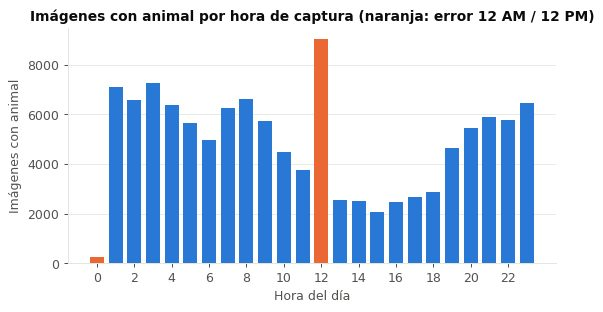

Imágenes con animal entre 19:00 y 05:59: 52.3%


In [11]:
fauna = images[~images['empty'] & images['datetime'].notna()]
hours = fauna['datetime'].dt.hour.value_counts().reindex(range(24), fill_value=0)

all_hours = images['datetime'].dt.hour.value_counts().reindex(range(24), fill_value=0)
print(f"Todas las imágenes: hora 00 = {all_hours[0]:,}, hora 12 = {all_hours[12]:,}, "
      f"promedio horas 01-11 = {all_hours[1:12].mean():,.0f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(hours.index, hours.values, color=[ORANGE if h in (0, 12) else BLUE for h in hours.index], width=0.75)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hora del día')
ax.set_ylabel('Imágenes con animal')
ax.set_title('Imágenes con animal por hora de captura (naranja: error 12 AM / 12 PM)')
ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'eda_hora_captura.png')
plt.show()

print(f"Imágenes con animal entre 19:00 y 05:59: {fauna['night'].mean():.1%}")

### Ejemplos: color e infrarrojo

La misma especie (coyote) en fotos a color y en infrarrojo. En infrarrojo la imagen pierde el color y suele tener menos contraste, lo que dificulta reconocer la especie.

Los ejemplos se eligen según el contenido de la imagen y no según la hora, porque la hora no es confiable:
- el error de 12 AM / 12 PM descrito arriba;
- algunas cámaras tienen el reloj mal configurado (por ejemplo, fotos de pleno día con el sello "9:33 PM" en la cámara 120);
- algunas cámaras (marca Cuddeback) usan flash blanco de noche, así que también hay fotos nocturnas a color.

Una foto se considera infrarroja si sus píxeles iluminados no tienen color (los tres canales casi iguales). Infrarrojo implica noche; color no implica necesariamente día.

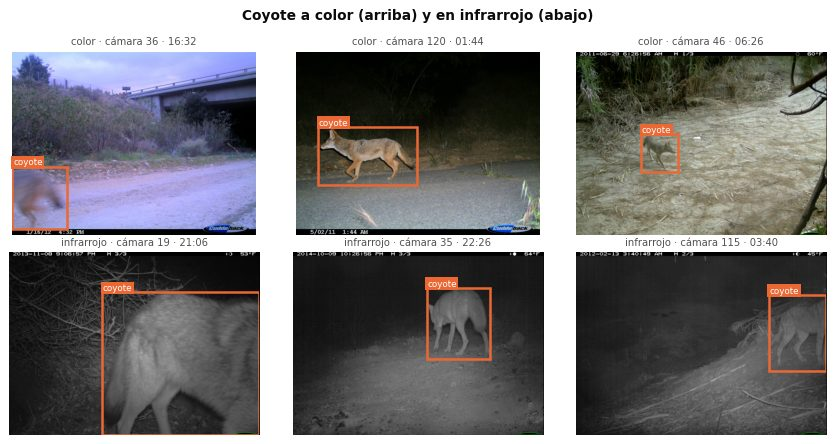

In [12]:
def is_infrared(file_name, tol=8):
    img = np.asarray(Image.open(image_path(file_name)).convert('RGB').resize((160, 120)), dtype=float)
    chroma = img.max(axis=2) - img.min(axis=2)
    lit = img.max(axis=2) > 40  # se ignora el fondo negro
    return chroma[lit].mean() < tol if lit.any() else True


coyote = boxes[boxes['species'] == 'coyote'].drop_duplicates('image_id').sample(frac=1, random_state=2)
picked = {False: [], True: []}
for img_id in coyote['image_id']:
    ir = is_infrared(by_id.loc[img_id, 'file_name'])
    if len(picked[ir]) < 3:
        picked[ir].append(img_id)
    if all(len(v) == 3 for v in picked.values()):
        break
examples = [{'file_name': by_id.loc[i, 'file_name'], 'boxes': boxes_of(i, boxes),
             'caption': caption(by_id.loc[i], f'{label} · ')}
            for ir, label in [(False, 'color'), (True, 'infrarrojo')] for i in picked[ir]]
show_examples(examples, 3, 'Coyote a color (arriba) y en infrarrojo (abajo)', 'eda_ejemplos_color_infrarrojo.png')

## Imágenes por cámara

Número de imágenes por cámara, ordenado de mayor a menor. Pocas cámaras concentran gran parte del dataset.

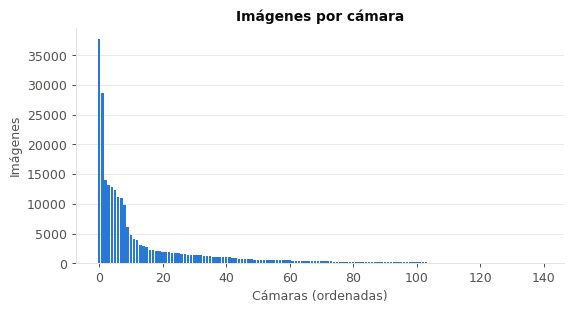

El 10 % de las cámaras (14) concentra el 70.9% de las imágenes


In [13]:
n = by_cam['imagenes'].sort_values(ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(n.index, n.values, color=BLUE, width=0.8)
ax.set_xlabel('Cámaras (ordenadas)')
ax.set_ylabel('Imágenes')
ax.set_title('Imágenes por cámara')
ax.grid(axis='x', visible=False)
fig.savefig(FIG / 'eda_imagenes_por_camara.png')
plt.show()

top = n.head(14).sum() / n.sum()
print(f'El 10 % de las cámaras (14) concentra el {top:.1%} de las imágenes')

## Imágenes excluidas

Motivos por los que una imagen queda fuera del entrenamiento y la evaluación (detalle por imagen en `results/dataset_exclusions.csv`):

- **animal_sin_caja**: la foto tiene la especie anotada a nivel de imagen pero ninguna caja. YOLO la aprendería como fondo.
- **cajas_imagen_completa**: fotos de "car", cuyas cajas son la imagen completa `[0, 0, W, H]` en vez de localizar el vehículo.
- **clase_excluida**: especies sin cajas suficientes (pig, cow, bat, insect).

En CCT la especie se anota por **secuencia** (ráfaga de 1 a 3 fotos), no por foto: si el animal sale del cuadro en uno de los disparos, esa foto igual queda etiquetada con la especie aunque no se vea ningún animal. Las etiquetas a nivel de imagen tienen ruido, lo que refuerza la decisión de entrenar y evaluar solo con imágenes que tienen caja.

motivo
animal_sin_caja          49801
cajas_imagen_completa     4717
clase_excluida            3637


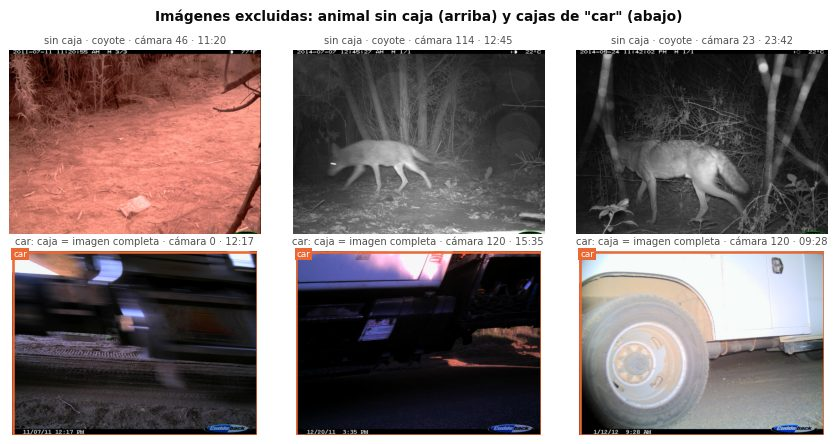

In [14]:
excl = pd.read_csv(ROOT / 'results' / 'dataset_exclusions.csv')
print(excl['motivo'].value_counts().to_string())

examples = []
for _, r in excl[excl['motivo'] == 'animal_sin_caja'].sample(3, random_state=3).iterrows():
    examples.append({'file_name': by_id.loc[r['image_id'], 'file_name'],
                     'caption': caption(by_id.loc[r['image_id']], f"sin caja · {r['etiquetas']} · ")})
car_ids = boxes_all.loc[boxes_all['species'] == 'car', 'image_id'].drop_duplicates().sample(3, random_state=3)
for img_id in car_ids:
    examples.append({'file_name': by_id.loc[img_id, 'file_name'],
                     'boxes': boxes_of(img_id, boxes_all[boxes_all['species'] == 'car']),
                     'caption': caption(by_id.loc[img_id], 'car: caja = imagen completa · ')})
show_examples(examples, 3, 'Imágenes excluidas: animal sin caja (arriba) y cajas de "car" (abajo)',
              'eda_ejemplos_excluidas.png')